# 综合项目

小兔鲜项目：项目前置样式与项目搭建（前端第09天）


本日开始小兔鲜项目。先补充精灵图、背景缩放、阴影和过渡，再认识网站骨架、SEO、图标和版心，最后搭建项目目录与公共样式，读懂配套代码中的快捷导航、头部和页脚。

依据：`day09-小兔鲜项目.rar` 中的58页课件 `day09（小兔鲜01-项目前置样式+项目搭建）v1.0.pdf`、同名XMind、课堂 `00`～`06` 案例，以及 `xtx_pc_client` 内的HTML、CSS和素材。[第02～10天资料分享](https://pan.baidu.com/s/1Cf1WISQ8Fc15xm7gf0VyBw?pwd=1234)，提取码 `1234`。

学习顺序：

1. CSS样式补充：精灵图、背景图片大小、文字阴影、盒子阴影、过渡。
2. 项目前置认知：网页与网站、HTML骨架、SEO三大标签、语义化布局、favicon、版心和CSS书写顺序。
3. 项目结构搭建：文件目录、样式分工、基础公共样式、首页骨架。
4. 配套项目代码：快捷导航、头部、搜索和购物车、页脚，以及本日检查。

本日资料没有单独的作业目录。配套首页实现的是公共区域，`index.css` 目前只有注释，商品与轮播主体尚未编写；已有大量商品素材不代表相应区域已实现。

**补充：** XMind内部标题残留“day08”，PDF和资料目录均为day09，本笔记使用第09天。课件目录名为 `xtx-pc-client`，配套源码目录实际为 `xtx_pc_client`；下文操作路径以配套源码为准。

代码用于阅读，均放在Markdown单元里。课堂的CSS与HTML分别放进 `<style>`、`<body>`；项目中的CSS保留为外部文件。代码中的图片路径依赖原案例文件夹，笔记中的教学图则已嵌入Notebook。


复习衔接：课堂 `00-复习.html` 回顾第08天的定位居中。

CSS（放在 `<style>` 内）：

```css
/* 定位盒子居中: left和top设置50%, 把盒子移动到浏览器的中间(盒子的左和顶到浏览器的中间) */
/* 把盒子向左和上移动宽度和高度的一半 */
.box {
    position: absolute;
    left: 50%;
    /* margin-left: -200px; */
    /* transform: translate(-50%); */

    top: 50%;
    /* margin-top: -150px; */
    transform: translate(-50%, -50%);

    /* margin: 0 auto; */
    width: 400px;
    height: 300px;
    background-color: pink;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

`left: 50%`、`top: 50%` 先把盒子的左上角移到参照区域中心，`translate(-50%, -50%)` 再按自身宽高各向左、向上移动一半。当前盒子是400px × 300px；注释中的负外边距分别为-200px、-150px，与尺寸匹配。

没有已定位祖先时，绝对定位参照初始包含块；不要把它和滚动时一直贴住可视区域的固定定位混淆。接下来的搜索图标和购物车角标会继续用到定位。


## 1. CSS 样式补充

这些样式用于补齐项目细节。精灵图解决多个小图标的取用，背景缩放决定图片如何适应盒子，阴影和过渡改善视觉与交互表现。


### 1.1 精灵图：多张小图合成一张图

项目中把多张小图片合并成一张大图片，这张图称为**精灵图**（CSS Sprite）。每个小图标显示在自己的盒子内，通过背景位置取出大图的对应区域。

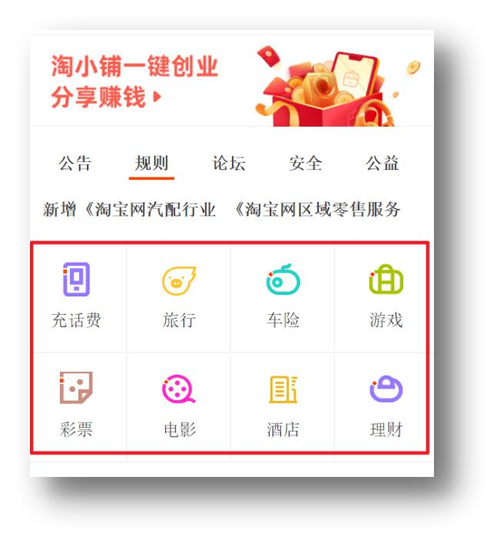

课件用8张小图说明：分别下载需要8次图片请求；合并成一张精灵图则可通过1次请求取得这些图标。多个元素引用同一张图，也可以复用已加载的资源。

**原课优点：** 减少图片请求次数，减轻服务器压力，有助于页面加载。

**补充：** 是否实际更快还取决于图片大小、缓存和网络条件，不能仅凭“合成一张图”保证速度提升。本日重点是掌握背景位置与取图方法。


### 1.2 精灵图的使用步骤

在原案例所在目录创建盒子，并按课件使用PxCook测量素材：

1. 测量目标小图的宽高，设置为盒子的宽高。
2. 把整张精灵图设为该盒子的背景图片。
3. 测量目标小图左上角在精灵图中的坐标 `(x, y)`。
4. 设置 `background-position: -x -y`，让目标区域移动到盒子左上角。

例如目标位于大图右侧3px处，为了让它对准盒子左侧，需要把大图向左移3px，因此位置取 `-3px`。位于下方90px的图标，则把背景向上移90px。

课堂 `01-CSS精灵图.html`：

CSS（放在 `<style>` 内）：

```css
span {
    display: inline-block;
    width: 18px;
    height: 24px;
    background-color: pink;
    background-image: url(./images/taobao.png);
    /* 背景图位置属性: 改变背景图的位置 */
    /* 水平方向位置  垂直方向的位置 */
    /* 想要向左侧移动图片, 位置取负数;  */
    background-position: -3px 0;
}

b {
    display: block;
    width: 25px;
    height: 21px;
    background-color: green;
    background-image: url(./images/taobao.png);
    background-position: 0 -90px;
}
```

HTML（放在 `<body>` 内）：

```html
<!-- <img src="./images/taobao.png" alt=""> -->
<!-- 精灵图的标签都用行内标签  span, b, i -->
<span></span>


<b></b>
```

原精灵图素材（24px × 595px）：



| 元素 | 显示尺寸 | 背景偏移 | 本例作用 |
| --- | --- | --- | --- |
| `span` | 18px × 24px | `-3px 0` | 显示最上方对应区域 |
| `b` | 25px × 21px | `0 -90px` | 显示约90px处对应区域 |

观察结果：两个元素显示同一张素材中的不同图标，而不是各自展示整张长图。粉色与绿色背景是辅助观察的底色。

**注意：** `span` 默认行内，宽高需要先转成行内块；课堂 `b` 则设置为块级。源码注释建议用 `span`、`b`、`i` 承载图标，这是示例选择，背景图也可以用于其他盒子。

**补充：** 当前代码未关闭背景重复，素材本身只有24px宽，而 `b` 为25px宽，可能在多出的区域出现重复像素。需要更干净的图标边界时，可在该元素加 `background-repeat: no-repeat`；原代码保持不改。


### 1.3 背景图片大小 background-size

`background-size` 改变背景图片的显示大小，不会改变盒子本身的尺寸。

```css
background-size: 宽度 高度;
```

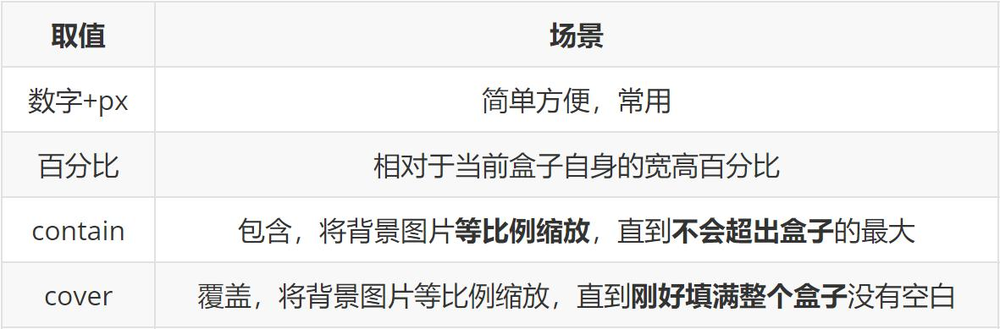

| 写法 | 含义 |
| --- | --- |
| `300px 200px` | 指定背景图宽和高 |
| `300px` | 指定宽，高度按原图比例自动计算 |
| `50%` | 宽按背景定位区域宽度的50%计算，高度自动 |
| `contain` | 等比例缩放，完整放入区域；比例不同可能留白 |
| `cover` | 等比例缩放，覆盖整个区域；比例不同可能裁掉部分图像 |

课堂 `02-背景图缩放.html`：

CSS（放在 `<style>` 内）：

```css
.box {
    width: 400px;
    height:300px;
    background-color: pink;
    background-image: url(./images/1.jpg);
    background-repeat: no-repeat;
    /* background-size: 300px; */
    /* background-size: 50%; */

    /* 如果图的宽或高与盒子的尺寸相同了, 另一个方向停止缩放 -- 导致盒子可能有留白 */
    background-size: contain;
    /* 保证宽或高和盒子尺寸完全相同 , 导致图片显示不全 */
    /* background-size: cover; */

    /* 工作中, 图的比例和盒子的比例都是相同的, contain 和cover效果完全相同; */
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

当前启用 `contain`，`cover`、300px和50%的写法都被注释。原图 `1.jpg` 是200px × 200px，盒子400px × 300px，因此当前背景等比例放大到300px × 300px，默认靠左上方，右侧留下100px底色。

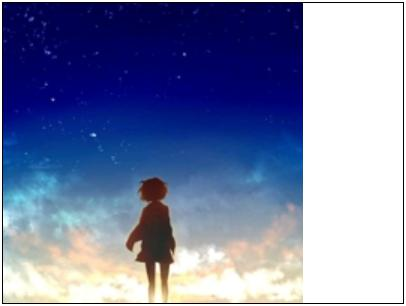

将 `contain` 改为 `cover` 后，原图会放大到400px × 400px；盒子仍高300px，超出盒子的部分看不到。将 `background-size: 50%` 启用时，本例图片宽度为200px，高度也为200px。

**补充：** 两个长度都指定时可能改变原图比例；单独指定宽度时高度默认 `auto`，不必把单值理解为同时指定相同的宽和高。

**补充：** 源码注释说“工作中图和盒子比例相同”，这是举例条件。实际素材比例可以不同；只有两者宽高比相同时，`contain` 与 `cover` 才会得到相同缩放尺寸。


### 1.4 background 连写中的缩放与覆盖

课件扩展前面的背景连写：位置与尺寸之间用 `/` 分隔。

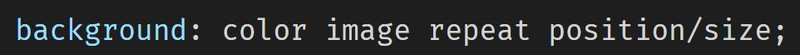

按原课语法整理的例子：

```css
.box {
    background: pink url('./images/1.jpg') no-repeat center / contain;
}
```

`center` 是背景位置，`contain` 是背景大小；不能省掉 `/` 把位置与大小直接连在一起。

**覆盖问题：** `background` 是简写，会同时设置或重置它包含的背景属性。即使后写的简写没有显式写尺寸，也可能把前面的 `background-size` 重置。

```css
.box {
    background-size: contain;
    background: pink url('./images/1.jpg') no-repeat center;
}
```

上面后写的简写使 `contain` 失效。原课给出两种解决方法：

1. 先写简写，再在下面单独写 `background-size: contain`。
2. 直接把 `contain` 放进简写的 `position / size` 部分。

查看代码时不能只确认某行写了尺寸，还要看下面是否有覆盖它的背景简写。


### 1.5 文字阴影 text-shadow

文字阴影沿文字形状显示，用于强调文字细节。原课参数顺序：水平偏移、垂直偏移、可选模糊半径、颜色。

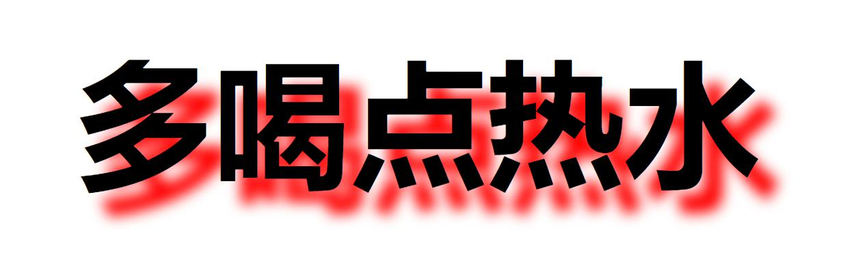

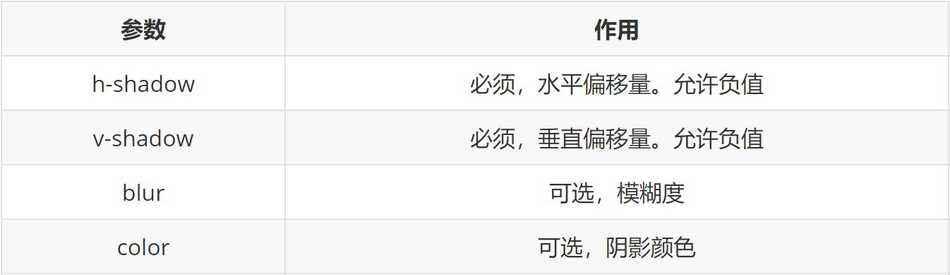

```css
text-shadow: 5px 5px 5px red;
```

| 参数 | 含义 |
| --- | --- |
| 第1个长度 | 水平偏移：正值向右，负值向左 |
| 第2个长度 | 垂直偏移：正值向下，负值向上 |
| 第3个长度 | 模糊半径，可省略；0表示不模糊 |
| 颜色 | 阴影颜色，可写颜色名或rgba等 |

资料没有单独的文字阴影HTML文件，以下按课件效果整理一个阅读示例：

```html
<h2>多喝点热水</h2>
```

```css
h2 {
    font-size: 60px;
    text-shadow: 5px 5px 5px red;
}
```

**原课拓展：** 多组阴影之间用逗号隔开，例如 `text-shadow: 2px 2px 3px red, -2px -2px 3px blue`。

水平和垂直偏移允许负值；模糊半径不能为负。文字阴影没有盒子阴影的扩展半径与 `inset` 参数，不能把两种语法混写。


### 1.6 盒子阴影 box-shadow

盒子阴影围绕盒子的形状显示。与文字阴影相比，多了扩展半径和内阴影选项。

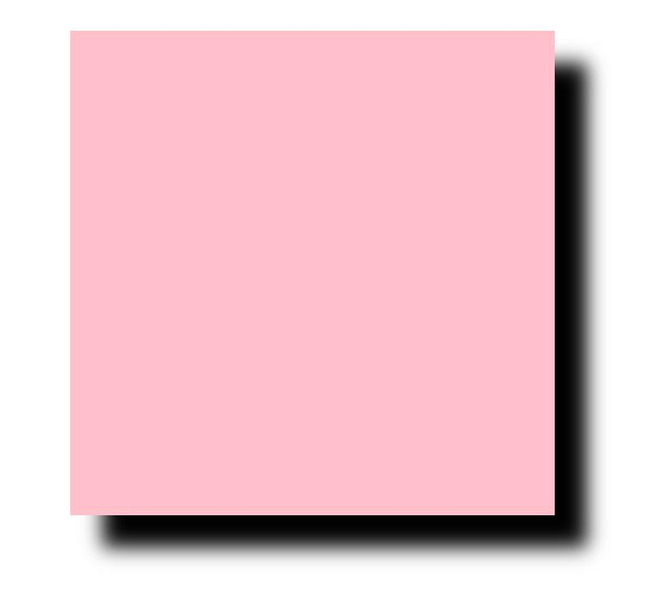

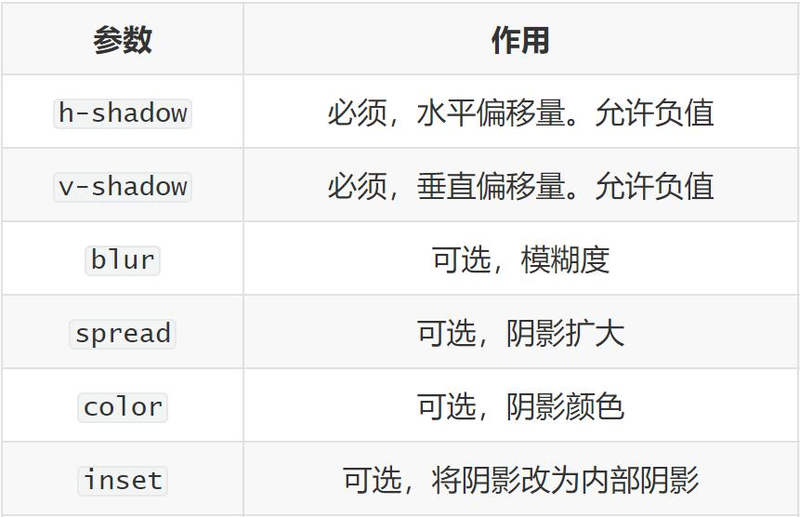

```css
box-shadow: 水平偏移 垂直偏移 模糊半径 扩展半径 颜色 inset;
```

前两个偏移长度必需；模糊、扩展、颜色、`inset` 可以按需求省略。`inset` 表示内阴影；默认是外阴影。

课堂 `03-盒子阴影.html`：

CSS（放在 `<style>` 内）：

```css
.box {
    width: 200px;
    height: 200px;
    background-color: pink;

    box-shadow: 5px 10px 20px 10px green inset;

    /* 注意: 外阴影, 不能添加outset, 添加了会导致属性报错 */
    /* box-shadow: 5px 10px 20px 10px green outset; */
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

**当前启用的效果是内阴影：** `5px 10px 20px 10px green inset`，偏移右5px、下10px，模糊20px、扩展10px，颜色绿色。PDF的配图则是外阴影，两者演示的状态不同。

尝试去掉末尾 `inset`，观察绿色外阴影。不要添加 `outset`：它不是 `box-shadow` 的合法外阴影关键词，整条声明会无效；原文件正是用注释提醒这一点。

**补充：** 模糊半径不能为负，扩展半径可以为负以收缩阴影。阴影是绘制效果，不像边框那样增加盒子的布局尺寸。


### 1.7 过渡 transition：从一种样式慢慢变到另一种

过渡需要样式发生变化，本课主要通过 `:hover` 从默认状态切换到悬停状态。把 `transition` 写在**发生变化的元素本身**上。

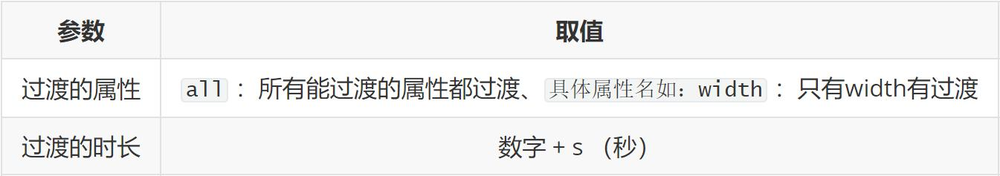

本课先掌握两个参数：

```css
transition: 过渡属性 过渡时间;
```

| 取值 | 含义 |
| --- | --- |
| `width 1s` | 宽度在1秒内过渡 |
| `width 1s, background-color 2s` | 宽度1秒，背景色2秒，各组用逗号隔开 |
| `all 1s` | 本例发生变化且可过渡的属性都使用1秒过渡 |

课堂 `04-过渡.html`：

CSS（放在 `<style>` 内）：

```css
/* 过渡配合hover使用, 谁变化谁加过渡属性 */
.box {
    width: 200px;
    height: 200px;
    background-color: pink;
    /* 宽度200, 悬停的时候宽度600, 花费1秒钟 */
    /* transition: width 1s, background-color 2s; */

    /* 如果变化的属性多, 直接写all,表示所有 */
    transition: all 1s;
}

.box:hover {
    width: 600px;
    background-color: red;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

**观察结果：** 默认粉色盒子宽200px；鼠标移入后宽度慢慢变到600px、背景慢慢变红；移出后又在1秒内恢复。当前启用的是 `all 1s`，分别设置两种时长的写法被注释。

如果没有定义不同的默认值与悬停值，仅写 `transition` 不会自动产生变化。给父元素加过渡，也不会自动替所有子元素的样式变化建立过渡。

**补充：** `all` 表示所有发生变化且可过渡的属性，不保证任意属性都能平滑变化。本日此前学过的宽度和颜色可以作为观察对象。


### 1.8 transition 放在默认状态还是 hover 状态

原课区分两种写法：

| 放置位置 | 本课例子的结果 |
| --- | --- |
| 默认 `.box` | 移入、移出均有过渡 |
| 只有 `.box:hover` | 移入有过渡；移出恢复默认时没有这条过渡声明 |

当前课堂版放在默认状态。如需对照第二种效果，将原来的声明移到悬停规则：

```css
.box {
    width: 200px;
    height: 200px;
    background-color: pink;
}
.box:hover {
    width: 600px;
    background-color: red;
    transition: all 1s;
}
```

鼠标移出时 `.box:hover` 不再匹配，默认规则没有设置过渡，所以本例会直接恢复。希望进出都平滑时，按课堂完成版放在默认状态。


## 2. 项目前置认知

从单个案例进入网站项目，需要认识页面的整体角色、头部信息和代码组织。下面按课件顺序整理。


### 2.1 网页与网站的关系

原课类比：网页是一页纸，网站是一本书。浏览时看到的是一页页内容，多页内容围绕同一主题组合成网站。

- **网页**：网站中的一页，如主页、登录页、商品页。
- **网站**：提供特定服务的一组网页，如购物网站、搜索网站、课程网站。

因此项目中的 `index.html` 只是首页；共享的头部和底部样式可以抽出，方便多个页面使用，而每页自己的内容仍分别组织。


### 2.2 HTML 骨架：声明、语言与字符编码

课堂 `05-html骨架.html`：

```html
<!DOCTYPE html>
<!-- 中文网站 -->
<html lang="zh-CN">
<head>
    <!--charset="UTF-8" 规定网页的字符编码  -->
    <meta charset="UTF-8">

    <!-- ie(兼容性差) / edge -->
    <meta http-equiv="X-UA-Compatible" content="IE=edge">

    <!-- 宽度 = 设备宽度 : 移动端网页的时候要用 -->
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
</head>
<body>
    
</body>
</html>
```

| 代码 | 本日含义与操作 |
| --- | --- |
| `<!DOCTYPE html>` | HTML文档类型声明，放在文档开头；它不是普通HTML标签 |
| `<html lang="zh-CN">` | 声明简体中文；英文页面常写 `en` |
| `<meta charset="UTF-8">` | 声明页面字符编码为UTF-8 |
| `X-UA-Compatible` | 原模板保留的旧IE兼容模式声明 |
| `viewport` | 原模板保留的视口设置，后续做移动页面时会用到 |

课件用DOCTYPE告诉浏览器HTML版本；实际写项目时保留 `<!DOCTYPE html>`，使浏览器按标准模式解析页面即可。

语言声明有助于浏览器与搜索引擎理解页面语言，不会自动把内容翻译成中文。保存文件的编码与打开时的解码要一致，才能避免乱码。

原课介绍UTF-8、GB2312、GBK：UTF-8可表达多种语言文字，GB2312与GBK用于汉字编码范围。开发中统一保存为UTF-8，再写UTF-8声明，不需要在项目中来回切换。

**补充：** 只把 `charset` 改为UTF-8，不会把原文件的实际编码自动转换为UTF-8。出现乱码时要同时检查编辑器保存编码。

**补充：** 源码注释中的 `IE=edge` 是旧IE选择其可用最高文档模式的值，不是切换为Microsoft Edge浏览器。本笔记保留原模板，不展开旧浏览器兼容。


### 2.3 SEO 简介与三大标签

SEO是Search Engine Optimization，即搜索引擎优化。课件希望通过页面信息和标签语义，让搜索引擎更容易理解网站内容。

原课列出的办法包括竞价排名、HTML后缀、标签语义化。本日实际操作集中在网页标题、描述和关键词：

| 名称 | 真实HTML写法 | 作用 |
| --- | --- | --- |
| title | `<title>...</title>` | 页面标题，浏览器标签页可见 |
| description | `<meta name="description" content="...">` | 概括页面内容 |
| keywords | `<meta name="keywords" content="...">` | 原课用于声明页面关键词 |

课堂 `06-SEO三大标签.html` 以京东为例：

```html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- meta:desc -->
    <meta name="description" content="京东JD.COM-专业的综合网上购物商城，为您提供正品低价的购物选择、优质便捷的服务体验。商品来自全球数十万品牌商家，囊括家电、手机、电脑、服装、居家、母婴、美妆、个护、食品、生鲜等丰富品类，满足各种购物需求。">
    <!-- meta:kw -->
    <meta name="keywords" content="网上购物,网上商城,家电,手机,电脑,服装,居家,母婴,美妆,个护,食品,生鲜,京东">
    <title>京东(JD.COM)-正品低价、品质保障、配送及时、轻松购物！</title>
    <!-- link:favicon : 浏览器标题栏图标 -->
    <link rel="shortcut icon" href="favicon.ico" type="image/x-icon">
</head>
<body>
    
</body>
</html>
```

`meta:desc`、`meta:kw` 是原代码注释中的编辑器缩写提示，不是最终页面中要输出的新标签。最终仍是带 `name` 和 `content` 的 `meta`。

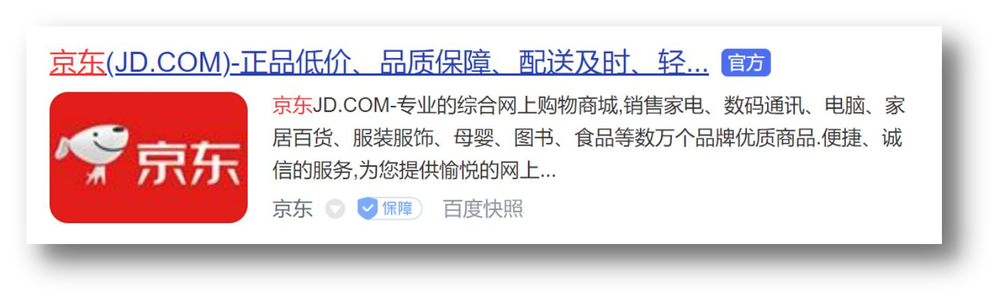

写小兔鲜项目时把京东信息换成小兔鲜本身的标题、描述和关键词，具体代码见 **3.4**。完成后首先能在浏览器标签页看到标题；搜索结果展示属于搜索引擎抓取后的行为，不能将图片当作本地打开页面的输出。

**补充：** 竞价属于付费广告，不等同自然搜索优化；页面使用 `.html` 后缀也不保证排名靠前。语义清晰、内容匹配才是本日能落实的工作。

**补充：** “SEO三大标签”是原课教学称呼，不代表三项都有相同排名作用。Google等主流搜索引擎不以 `meta keywords` 作为排名依据，description也不保证被原样采用为摘要；笔记保留课程写法，不承诺排名效果。


### 2.4 原课拓展：有语义的布局标签

HTML提供了表达不同内容角色的布局标签。本课先按头部、导航、侧栏、文章等区域认识它们。

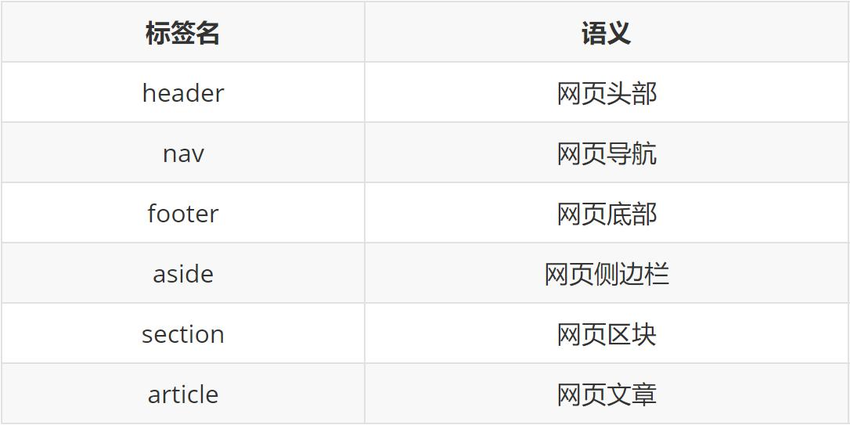

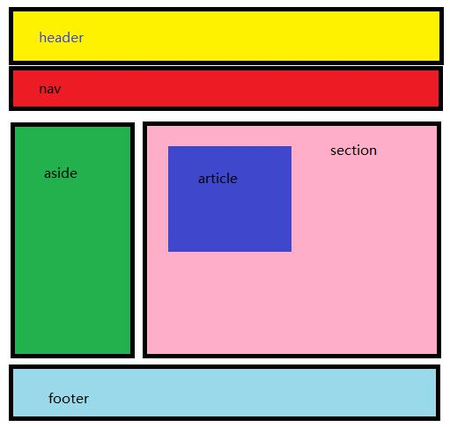

| 标签 | 原课含义 |
| --- | --- |
| `header` | 头部区域 |
| `nav` | 导航区域 |
| `footer` | 底部区域 |
| `aside` | 侧边辅助内容 |
| `section` | 主题区块 |
| `article` | 文章或可独立理解的内容 |

这些元素默认通常像 `div` 一样呈块级，但增加了内容语义。选择标签时看区域含义，位置和尺寸仍由CSS控制；把 `div` 改成 `nav` 不会自动排出横向导航。

**原源码使用方式：** 小兔鲜配套文件仍用带 `.shortcut`、`.header`、`.footer` 类的 `div` 组织区域。本笔记忠实摘录当前结构，不把它默默改成另一套标签。


### 2.5 网页标签页图标 favicon

favicon是浏览器标签页标题旁的小图标，原课习惯使用 `.ico` 格式，并将文件放在项目根目录。

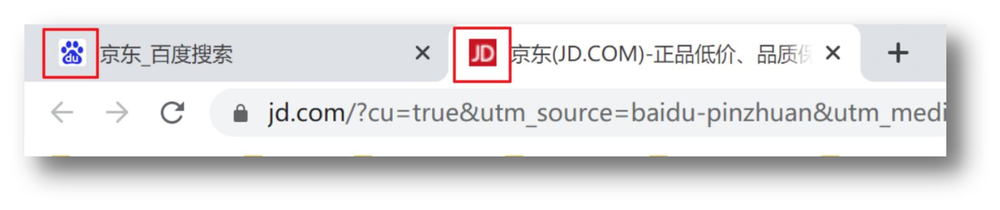

在 `index.html` 的 `<head>` 中写：

```html
<link rel="shortcut icon" href="favicon.ico" type="image/x-icon">
```

本地操作：把原资料的 `favicon.ico` 放在 `xtx_pc_client/index.html` 同一级；确认文件实际存在，再打开页面观察标签页图标。

`rel` 指定资源关系，`href` 是图标地址，`type` 说明文件类型。编辑器可以用原课的 `link:favicon` 缩写生成写法。

**常见错误：** 图标放在 `images` 目录却仍写根目录路径；文件被保存成其他名字；把图标代码放在普通页面内容里。改过图标却没看到更新时，可先刷新检查，浏览器缓存也会影响显示。


### 2.6 版心公共类

版心把页面主体内容约束到中间的固定宽度区域。类名常用 `container`、`wrapper` 或 `w`，项目中统一选一种即可。

小兔鲜原源码 `xtx_pc_client/css/common.css` 的版心：

```css
/* 各个页面相同的样式表 : 头, 尾部 */
/* 版心 */
.wrapper {
    width: 1240px;
    margin: 0 auto;
}
```

`width: 1240px` 确定主体宽度；`margin: 0 auto` 在外层有足够空间时分配左右外边距，使其水平居中。

通栏和版心分工：外层 `.shortcut` 提供整行背景，内部 `.wrapper` 约束内容；头部则在同一个元素上同时使用 `.header wrapper` 两个类。可以让多个区域共享版心，不必逐处重写宽度。

**补充：** 固定1240px版心不等于自动适应任意窄屏。窗口不足以容纳固定宽度时，仍可能出现横向溢出；课件“不同大小屏幕都能看到主体”应结合其固定宽度PC页面场景理解。


### 2.7 CSS 书写顺序与选择器习惯

原课建议按职责分组：先布局，再盒模型和背景，然后文字，最后细节装饰。

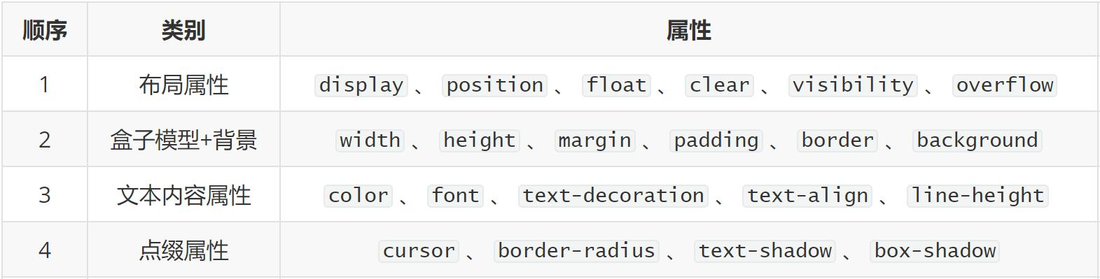

| 顺序 | 属性类别 | 例子 |
| --- | --- | --- |
| 1 | 布局 | `display`、`position`、`float`、`clear`、`visibility`、`overflow` |
| 2 | 盒模型与背景 | `width`、`height`、`margin`、`padding`、`border`、`background` |
| 3 | 文本 | `color`、`font`、`text-decoration`、`text-align`、`line-height` |
| 4 | 装饰 | `cursor`、`border-radius`、`text-shadow`、`box-shadow` |

```css
.card {
    position: relative;
    width: 200px;
    height: 200px;
    background-color: pink;
    font-size: 16px;
    color: #333;
    border-radius: 10px;
}
```

原课建议多使用类选择器配合后代关系，一个选择器中的类尽量不超过3个，避免为了匹配而把整条DOM路径都写进去。这是项目可读性习惯，不是浏览器的语法数量上限。

**补充：** 属性按类别排序主要让代码容易阅读和维护，不能仅凭这种顺序就承诺浏览器渲染性能提高。同一属性的覆盖关系、简写与单独属性的先后顺序仍要按实际CSS规则判断。

XMind另列“企业开发流程”“协同岗位”“查阅MDN文档”，本日PDF与代码没有给出对应的详细流程。本笔记保留原课具体可操作的内容，不根据这些目录词自行扩展。


## 3. 项目结构搭建

先准备目录和公共样式，再搭首页骨架。文件分工清晰后，公共区域与首页内容可以分别维护。


### 3.1 文件和目录准备

按原课步骤：

1. 创建项目文件夹，在VS Code中打开；所有项目相关文件放在该目录下。
2. 把 `favicon.ico` 放在项目根目录。
3. 复制原素材 `images` 与 `uploads` 目录。
4. 在根目录新建 `index.html`。
5. 新建 `css` 目录及 `base.css`、`common.css`、`index.css`。

课件目录示意：

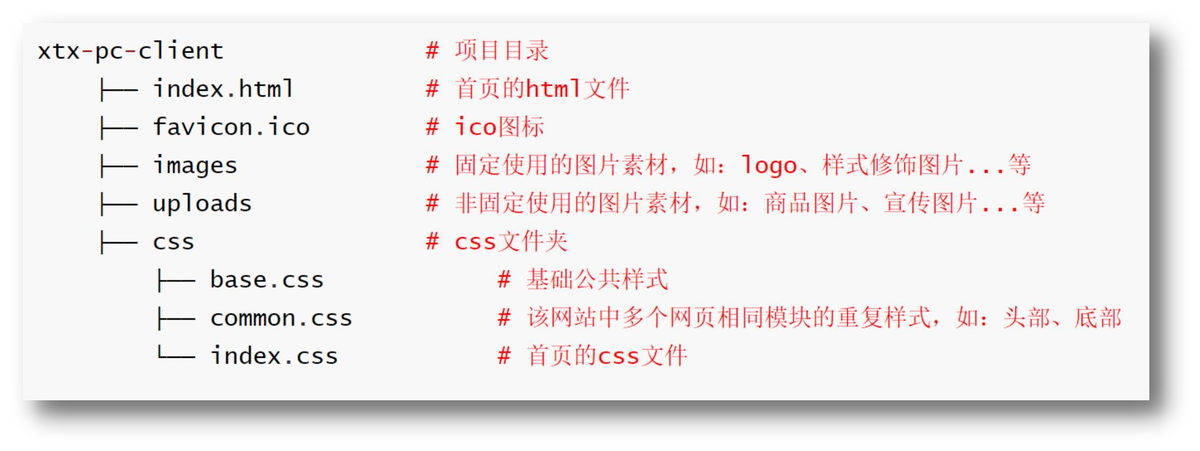

配套源码使用的真实结构：

```text
xtx_pc_client/
├── index.html
├── favicon.ico
├── css/
│   ├── base.css
│   ├── common.css
│   └── index.css
├── images/
│   ├── logo.png
│   └── sprites.png
└── uploads/
    ├── banner_1.png
    ├── new_goods_1.jpg
    ├── qrcode.png
    └── 其他商品与宣传素材
```

原课不建议项目名使用中文。本资料目录是下划线名称，图中是连字符名称，二者都是名称约定；不要在同一次操作中混用而找错文件。

**素材分工：** `images` 放logo、精灵图等网站固定装饰素材；`uploads` 放商品图、宣传图等业务内容素材。这里的 `uploads` 是课程静态素材分类，不代表已经做了上传功能。


### 3.2 三个CSS文件的职责与引入顺序

| 文件 | 职责 | 本日原代码状态 |
| --- | --- | --- |
| `base.css` | 基础初始化、统一默认样式和通用工具类 | 已提供完整代码 |
| `common.css` | 网站多个页面共享的模块样式，如头部、页脚 | 已有版心、快捷导航、头部、页脚 |
| `index.css` | 首页独有区域的样式 | 只有说明注释 |

`xtx_pc_client/css/index.css` 原内容：

```css
/* 放index页面的样式表 */
```

在 `index.html` 中依次引入：

```html
<link rel="stylesheet" href="./css/base.css">
<link rel="stylesheet" href="./css/common.css">
<link rel="stylesheet" href="./css/index.css">
```

先基础，再公共模块，最后首页。在相同层叠条件与相同选择器权重下，后写的规则可以覆盖前面的同一属性。

**补充：** 原注释“外链式样式表后写的生效”需要这个前提，不能忽略选择器权重等条件，认定后一张样式表永远覆盖前一张的所有声明。

**路径注意：** HTML中的 `./css/common.css` 相对HTML所在目录；CSS里的 `url(../images/sprites.png)` 相对该CSS文件所在目录。两者参照文件不同。


### 3.3 base.css：认识基础公共样式

项目开始前先消除常用标签默认样式差异，再统一当前项目需要的基础样式。课件要求认识已经准备好的代码，项目中可直接引入。

文件：`xtx_pc_client/css/base.css`。

```css
/* 清除默认样式的代码 */
/* 去除常见标签默认的 margin 和 padding */
body,
h1,
h2,
h3,
h4,
h5,
h6,
p,
ul,
ol,
li,
dl,
dt,
dd,
input {
  margin: 0;
  padding: 0;
}

/* 內减模式 */
* {
    box-sizing: border-box;
}

/* 设置网页统一的字体大小、行高、字体系列相关属性 */
body {
  font: 16px/1.5 "Helvetica Neue", Helvetica, Arial, "Microsoft Yahei",
    "Hiragino Sans GB", "Heiti SC", "WenQuanYi Micro Hei", sans-serif;
  color: #333;
}

/* 去除列表默认样式 */
ul,
ol {
  list-style: none;
}

/* 去除默认的倾斜效果 */
em,
i {
  font-style: normal;
}

/* 去除a标签默认下划线，并设置默认文字颜色 */
a {
  text-decoration: none;
  color: #333;
}

/* 设置img的垂直对齐方式为居中对齐，去除img默认下间隙 */
img {
  vertical-align: middle;
}

/* 去除input默认样式 */
input {
  border: none;
  outline: none;
  color: #333;
}

/* 左浮动 */
.fl {
  float: left;
}

/* 右浮动 */
.fr {
  float: right;
}

/* 双伪元素清除法 */
.clearfix::before,
.clearfix::after {
  content: "";
  display: table;
}
.clearfix::after {
  clear: both;
}
```

| 代码部分 | 解决什么问题 |
| --- | --- |
| 常用标签 `margin: 0; padding: 0` | 去掉body、标题、段落、列表等默认间距 |
| 全局 `box-sizing: border-box` | 宽高中计入边框与内边距，方便按设计尺寸布局 |
| `body` 的font与color | 统一16px字号、1.5倍行高、候选字体和文字颜色 |
| `ul, ol { list-style: none }` | 去掉列表标记 |
| `em, i { font-style: normal }` | 去掉默认斜体，便于按项目需求使用 |
| `a` 的下划线与颜色 | 建立项目统一链接外观 |
| `img { vertical-align: middle }` | 调整行内图片对齐，处理常见底部缝隙 |
| `input` 的border、outline与color | 清理原生外观，交给具体模块补样式 |
| `.fl`、`.fr` | 左、右浮动工具类 |
| `.clearfix` 双伪元素 | 清除浮动影响，让父盒子包住浮动子元素 |

`font: 16px/1.5 ...` 中的 `/1.5` 表示行高倍率；后面多个字体是依次尝试的候选列表，最终由系统已有字体决定。

**使用清浮动：** 在需要由浮动内容撑开高度的父盒子加 `class="clearfix"`；不是在每个浮动子元素上各加一次。本日快捷导航与头部已设固定高度，不靠它们自动撑高来布局。

**补充：** 原重置并不是对所有HTML元素清除所有默认行为，只处理列出的标签与规则。`input { outline: none }` 会去掉原焦点提示；若用于实际可交互页面，应在控件的焦点状态补可见提示。本笔记保留原代码。


### 3.4 首页骨架与完整HTML参考

课件第56页首页骨架把页面语言、标题、描述、关键词、favicon与三个CSS文件集中到 `<head>`。

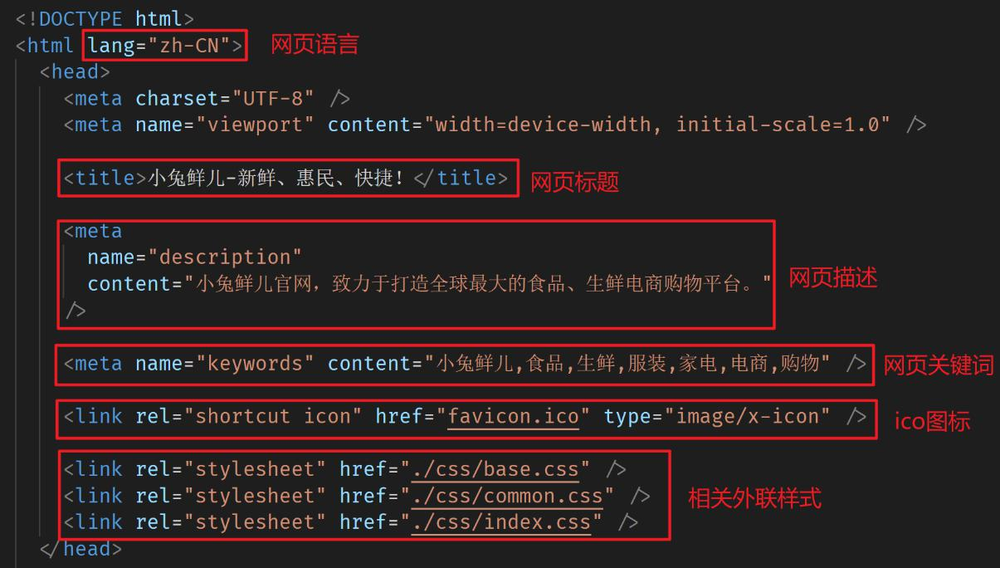

下面是配套 `xtx_pc_client/index.html` 的完整内容。后续章节直接对应其中的快捷导航、头部和页脚：

```html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <!-- meta:desc -->
    <meta name="description" content="小兔鲜儿官网，致力于打造全球最大的食品、生鲜电商购物平台">
    <!-- meta:kw -->
    <meta name="keywords" content="小兔鲜儿,食品,生鲜,服装,家电,电商,购物">
    <title>小兔鲜儿-新鲜、惠民、快捷！</title>
    <!-- link:favicon -->
    <link rel="shortcut icon" href="favicon.ico" type="image/x-icon">
    <!-- 按顺序引入: 外链式样式表后写的生效 -->
    <link rel="stylesheet" href="./css/base.css">
    <link rel="stylesheet" href="./css/common.css">
    <link rel="stylesheet" href="./css/index.css">
</head>
<body>
    <!-- 快捷导航 -->
    <div class="shortcut">
        <div class="wrapper">
            <ul>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">请先登录</a></li>
                <li><a href="#">请先登录</a></li>
                <li><a href="#"><span></span>请先登录</a></li>
            </ul>
        </div>
    </div>

    <!-- 头部 -->
    <div class="header wrapper">
        <div class="logo">
            <h1><a href="#">小兔鲜儿</a></h1>
        </div>
        <div class="nav">
            <ul>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
                <li><a href="#">首页</a></li>
            </ul>
        </div>
        <div class="search">
            <input type="text" placeholder="搜一搜">
            <!-- 定位 放大镜 -->
            <span></span>
        </div>
        <div class="car">
            <span>2</span>
        </div>
    </div>

    <!-- 版权区域 -->
    <div class="footer">
        <div class="wrapper">
            <div class="top">
                <ul>
                    <li>
                        <!-- 通过伪元素添加标签实现精灵图 -->
                        <span>价格亲民</span>
                    </li>
                    <li>
                        <span>价格亲民</span>
                    </li>
                    <li>
                        <span>价格亲民</span>
                    </li>
                </ul>
            </div>
            <div class="bottom">
                <p>
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> |
                    <a href="#">关于我们</a> 
                </p>
                <p>CopyRight @ 小兔鲜儿</p>
            </div>
        </div>
    </div>
</body>
</html>
```

头部信息已换成小兔鲜：标题“小兔鲜儿-新鲜、惠民、快捷！”，description说明网站定位，keywords列出相关词。

**资料差异：** PDF骨架使用 `lang="zh-CN"`，配套 `index.html` 仍为 `lang="en"`。上面保留源文件；自己搭中文页面时，可按课件骨架改为 `zh-CN`，声明应与实际文字语言一致。

**当前HTML状态：** 快捷导航的7个链接都使用“请先登录”；主导航9项都为“首页”；页脚3项都为“价格亲民”；底部链接重复“关于我们”。它们是课堂占位文字，不表示设计的各栏目内容都已经填完。所有链接暂时使用 `href="#"`，不是完整业务入口。

直接打开原项目的 `index.html`，可查看下节公共区域。此阶段没有商品主体，页脚会紧接头部；看到这种布局是配套源码当前的结果。


## 4. 配套项目公共区域

PDF主线到首页骨架结束，但本日配套 `common.css` 和HTML已写出公共区域，XMind也列了快捷导航目标。本节按页面从上到下解释已有代码，CSS摘录拼起来就是原 `common.css`。


### 4.1 快捷导航：通栏背景、版心、右侧链接

在 `xtx_pc_client/css/common.css` 中，版心代码见 **2.6**，下面是紧随其后的快捷导航部分：

```css
/* 快捷导航 */
.shortcut {
    height: 52px;
    background-color: #333;
}

.shortcut .wrapper {
    height: 52px;
}

/* 目的: 所有的文字内容居右侧对齐 */
.shortcut .wrapper ul {
    float: right;
}

/* 目的: 让所有的文字在一行显示 */
.shortcut .wrapper li {
    float: left;
    line-height: 52px;
}

.shortcut .wrapper a {
    padding: 0 16px;
    border-right: 1px solid #666;
    font-size: 14px;
    color: #dcdcdc;
}

.shortcut .wrapper a span {
    display: inline-block;
    margin-right: 8px;
    width: 11px;
    height: 16px;
    background-image: url(../images/sprites.png);
    background-position: -160px -70px;

    vertical-align: middle;
}

/* 清除a的边框线: 最后一个li里面的a */
.shortcut .wrapper li:last-child a {
    border: 0;
}
```

HTML对应 **3.4** 中 `.shortcut > .wrapper > ul > li > a` 的结构。实现顺序：

1. 外层 `.shortcut` 高52px，深灰背景铺满一行。
2. 内部 `.wrapper` 保持1240px宽和52px高，约束内容。
3. `ul` 右浮动，把整个链接组推到版心右边。
4. 各 `li` 左浮动，组成横排；`line-height: 52px` 让单行文字在这条导航内居中。
5. 链接左右各16px内边距，右边框做分隔线。
6. 只移除最后一个 `li` 内链接的边框。

最后一个链接有 `span` 图标。它设为11px × 16px行内块，引用项目精灵图，位置 `-160px -70px`，右边留8px；`vertical-align: middle` 协调图标与文字的对齐。

本项目原精灵图为400px × 400px，以下合成灰底以看清原图中的白色图标，图标像素与坐标保持不变：

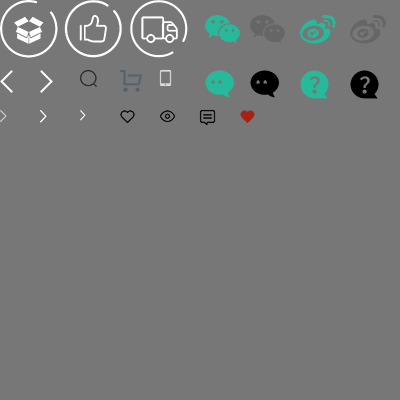

**观察结果：** 页面顶部出现整行深灰色条，链接组在1240px内容区域右侧，最后一项前有手机图标，末尾没有分隔线。

选择器 `.shortcut .wrapper li:last-child a` 读作：选快捷导航版心里最后一个li内部的a。这里去边框是已有结构的条件选择，不需要给最后一项额外写class。


### 4.2 头部整体与 logo

对应HTML中的 `<div class="header wrapper">`。两类共用一个盒子：`.wrapper` 提供1240px版心，`.header` 提供上下外边距和高度。

```css
/* 头部 */
.header {
    margin: 30px auto;
    height: 70px;
}

.logo {
    float: left;
    width: 207px;
    height: 70px;
}

/* logo 搜索引擎优化做法 */
.logo h1 {
    width: 207px;
    height: 70px;
}

.logo h1 a {
    display: block;
    width: 207px;
    height: 70px;
    background-image: url(../images/logo.png);
    background-size: contain;
    /* 目的: 让h1里面的字看不见 */
    font-size: 0;
}
```

头部高70px、上下外边距30px。logo左浮动，区域宽207px、高70px，HTML为 `.logo > h1 > a`。

原课logo做法：

- 用 `h1` 包住品牌链接，链接中保留文字“小兔鲜儿”。
- 链接转块级，设定207px × 70px区域，背景使用 `logo.png`。
- `background-size: contain` 让logo等比例放入链接区域。
- `font-size: 0` 隐去文字的视觉显示，避免文字叠在背景logo上。

原 `logo.png` 为774px × 260px，比显示区域大，因此本例需要缩放。改变图片文件尺寸不等同改变链接盒子大小。

**补充：** 这是原课程称为“logo搜索引擎优化”的结构写法，不保证单靠 `h1` 或隐藏文字就提高排名。笔记按当前实现解释。

**观察结果：** logo出现在版心左侧，品牌文字不再叠在图上，链接区域保持70px高。背景图若没有出现，先检查从 `css/common.css` 返回上一级的 `../images/logo.png` 路径。


### 4.3 主导航：横向排列与悬停下边线

紧接logo后的 `.nav` 左浮动，和logo共处头部一行。

```css
.nav {
    float: left;
    margin-left: 40px;
    height: 70px;
}

.nav li {
    float: left;
    margin-right: 48px;
    line-height: 70px;
}

.nav li a {
    padding-bottom: 7px;
}


.nav li a:hover {
    color: #27ba9b;
    border-bottom: 1px solid #27ba9b;
}
```

HTML为 `.nav > ul > li > a`，当前9项均使用“首页”占位。

布局参数：导航左外边距40px，各li右外边距48px、行高70px。链接 `padding-bottom: 7px` 给悬停下边线与文字留出距离。

鼠标悬停链接时，文字变为 `#27ba9b`，并出现同色1px下边框。当前没有给它设置 `transition`，颜色与边框按普通悬停切换；不要因为本日学习过过渡，就假定所有项目悬停都已加过渡。

**检查：** 主导航应和logo同排；若修改栏目文字后最后几项换行，先检查总宽度、项目数量、间距，而不是给导航随意再加绝对定位。


### 4.4 搜索框：输入内边距给放大镜让位

搜索区域位于主导航之后，仍参与头部的左浮动排列。

```css
.search {
    position: relative;
    float: left;
    margin-top: 24px;
    margin-left: 34px;
    width: 172px;
    height: 30px;
    border-bottom: 2px solid #e7e7e7;
}

.search input {
    padding-left: 30px;
    width: 172px;
    height: 28px;
}

.search input::placeholder {
    font-size: 14px;
    color: #ccc;
}

.search span {
    position: absolute;
    left: 2px;
    top: 0;
    /* display: inline-block; */
    width: 18px;
    height: 18px;
    background-image: url(../images/sprites.png);
    background-position: -79px -69px;
}
```

对应HTML：

```html
<div class="search">
    <input type="text" placeholder="搜一搜">
    <!-- 定位 放大镜 -->
    <span></span>
</div>
```

实现逻辑：

1. 搜索盒子相对定位，宽172px、高30px；顶部外边距24px，使它对齐头部。
2. 底部2px边框画出输入区域下边线。
3. input宽172px、高28px，`padding-left: 30px` 给图标留位置。
4. `input::placeholder` 单独设置14px、浅灰色提示文字。
5. span绝对定位，左2px、上0，18px × 18px，用 `sprites.png` 的 `-79px -69px` 取放大镜。

全局 `border-box` 使input的172px宽已经包含左内边距，不需再额外加30px到总宽度中。绝对定位的图标不占输入文字位置，所以左内边距是主动让位的步骤。

**当前效果与边界：** 输入框可输入，placeholder显示“搜一搜”；放大镜只是装饰，不是按钮，HTML没有表单提交或搜索逻辑。`display: inline-block` 在此源码中被注释，图标通过绝对定位设置宽高。


### 4.5 购物车与数量角标

头部最后的 `.car` 是购物车图标区域，里面的span显示数字2。

```css
.car {
    position: relative;
    float: left;
    margin-top: 28px;
    margin-left: 15px;
    width: 23px;
    height: 23px;
    background-image: url(../images/sprites.png);
    background-position: -119px -69px;
}

.car span {
    /* 绝对定位, 盒子具备行内块特点 */
    position: absolute;
    right: -13px;
    top: -6px;
    width: 20px;
    height: 15px;
    background-color: #e26237;
    border-radius: 8px;

    font-size: 13px;
    color: #fff;
    text-align: center;
    line-height: 15px;
}
```

购物车自身左浮动，宽高23px；背景位置 `-119px -69px` 取购物车图标。它还设置相对定位，让数量span能以它为参照。

数量角标绝对定位：`right: -13px`、`top: -6px` 使它伸到图标右上方；20px × 15px、橙色背景、8px圆角、白色13px文字。`text-align: center` 加15px行高让数字在这个小区域中对齐。

**观察结果：** 图标仍参与头部排列，角标叠在它的右上方，数字不会把搜索框或购物车主体挤开。

**补充：** 源码用“绝对定位具备行内块特点”解释宽高生效，这是部分行为类比，不表示它实际改成 `display: inline-block`。

目前数字2是HTML固定文字，没有读取真实购物车数量；`.car` 本身是 `div`，也没有实现点击跳转。数量增加到更多位数时需要按设计重新检查角标宽度，不宜直接认定20px足够所有内容。


### 4.6 页脚顶部：伪元素加精灵图

以下是 `common.css` 的页脚外层与顶部部分：

```css
/* 版权footer */
.footer {
    height: 342px;
    background-color: #333;
}

.footer .wrapper {
    width: 1393px;
}

.footer .top {
    padding-top: 59px;
    padding-left: 135px;
    height: 175px;
    border-bottom: 3px solid #434343;
}

.footer .top li {
    position: relative;
    float: left;
    margin-right: 300px;
    width: 195px;
    height: 58px;

    line-height: 58px;
}

.footer .top li:last-child {
    margin-right: 0;
}

/* 伪元素添加的标签  行内 */
/* 如果行内块和行内文字无法通过vertical-align或行高对齐, 定位 */
.footer .top li::before {
    position: absolute;
    left: 0;
    top: 0;
    /* display: inline-block; */
    content: '';
    width: 58px;
    height: 58px;
    background-image: url(../images/sprites.png);
    vertical-align: middle;
}

.footer .top li span {
    margin-left: 77px;
    font-size: 28px;
    color: #fff;
}

/* 第二个li里面的berfore添加背景图位置属性 */
.footer .top li:nth-child(2)::before {
    background-position: -64px 0;
}
```

外层 `.footer` 高342px、深灰背景。这里的 `.footer .wrapper` 将版心宽度覆盖为1393px，和前面1240px公共版心不同；源码就是这样设置，不能在笔记中默认它们同宽。

顶部高175px，顶部内边距59px、左内边距135px，底部3px分隔边框。li左浮动，宽195px、高58px，前两项右外边距300px，最后一项取消右外边距。

按本例全局 `border-box` 计算，三个li加两个间隔共 `195 × 3 + 300 × 2 = 1185px`；父级左内边距使内容可用宽度为 `1393 - 135 = 1258px`，能够排在同一行。

图标无需在HTML里另写图片标签：

1. `li::before` 用 `content: ''` 生成一个用于装饰的伪元素。
2. li相对定位，伪元素绝对定位贴左上，宽高58px。
3. 精灵图默认位置为左上，取出第一个服务图标。
4. 文字span使用 `margin-left: 77px` 给图标及间距让位，28px白字、58px行高。
5. 第二个li的伪元素设置 `background-position: -64px 0`，显示第二个图标。

**当前源码的未完成细节：** 没有第三个li的单独背景位置，所以第三项仍显示第一个图标；三项文字也都为“价格亲民”。这里保留原文件，不凭常见小兔鲜设计替它补全。

**补充：** `::before` 模拟生成内容，并没有真的新增HTML标签。当前伪元素是绝对定位，`vertical-align: middle` 不是决定它位置的关键，实际靠 `left: 0; top: 0` 定位。


### 4.7 页脚底部：链接与版权

`common.css` 最后一部分：

```css
.footer .bottom {
    padding-top: 40px;
    font-size: 14px;
    color: #999;
    text-align: center;
}

.footer .bottom a {
    font-size: 14px;
    color: #999;
}

.footer .bottom p {
    margin-bottom: 20px;
}
```

对应 **3.4** 中 `.footer .bottom`：第一段有7个“关于我们”链接，以文本 `|` 分隔；第二段为 `CopyRight @ 小兔鲜儿`。

底部上内边距40px、字号14px、灰色文字、水平居中；a也单独设灰色，覆盖基础文件中链接默认的 `#333`。每个p有20px下外边距。

**观察结果：** 页脚上方为三项图标和文字，下方为居中的链接行与版权行。原版权文字保留 `@`；本日不要将它当成已确定的最终版权文案。

页脚位于普通文档流，并没有使用 `position: fixed` 固定到浏览器底部。当前主体区还空着，所以它直接接在头部后面；这和“固定底部”是不同效果。


### 4.8 项目阅读与验证顺序

在原资料的 `01-案例/xtx_pc_client` 目录检查：

1. 确认 `index.html`、favicon、三个CSS文件、logo和精灵图都在对应目录。
2. 打开 `index.html`：标题应为小兔鲜，页面字体与默认间距受 `base.css` 影响。
3. 检查52px快捷导航及右侧链接；最后一项有手机图标、无分隔边框。
4. 检查70px头部中的logo、导航、搜索、购物车和数字角标。
5. 悬停主导航，检查绿色文字和下边线；输入框提示文字应为“搜一搜”。
6. 检查页脚的三项图标文字、链接和版权，记住第三图标尚未切换。
7. 缩窄窗口，观察固定版心的横向溢出；该源码没有实现自适应布局。

精灵图不对时，先检查宽高和坐标；全部背景图消失时，先检查CSS内部路径；所有样式消失时，先检查HTML的三个link。不要把文件缺失、坐标错位和布局尺寸混为同一个问题。

本日素材中的轮播和商品图仍未被当前HTML引用，`index.css` 也还空着。练习以读懂和复现已有公共区域为准，不在这一篇补写下一阶段商品主体。


### 4.9 本日复习检查

| 要回答的问题 | 应说清的内容 |
| --- | --- |
| 精灵图如何取出一个小图？ | 盒子按小图尺寸设置；背景用整图；坐标取负值 |
| 背景缩放与盒子缩放是否相同？ | background-size只改变背景图片，不改变盒子尺寸 |
| contain与cover怎样选择？ | 完整放入可能留白；覆盖区域可能裁切 |
| background简写如何写size？ | position后加 `/ size`，留意简写重置前面的单独属性 |
| 文字阴影和盒子阴影有何区别？ | 文字形状与盒子形状；盒子还可设置spread、inset |
| 外阴影能写outset吗？ | 不能；外阴影直接省略inset |
| transition写在哪里？ | 写在变化的元素本身；默认状态可让移入移出都过渡 |
| SEO三项真实标签是什么？ | title标签；description、keywords两个meta |
| 页面语言与编码怎么写？ | 中文可用zh-CN，文件保存与meta统一UTF-8 |
| favicon路径相对谁？ | 当前HTML文件 |
| CSS里的背景路径相对谁？ | 写这条声明的CSS文件 |
| base、common、index如何分工？ | 初始化；多页面公共模块；首页专属样式 |
| 浮动列表为什么有两层浮动？ | ul把整体推右，li让项目横排 |
| 搜索图标为何不压到文字？ | 绝对定位叠放，input用左内边距让位 |
| 购物车数字为何跟着图标？ | car相对定位，span绝对定位 |
| 页脚第三图标为何重复？ | 当前只为第二项设置不同背景位置 |
| 本日完整首页是否已完成？ | 公共区域已写，主体商品区和首页CSS尚未实现 |

练习时先独立做两个精灵图盒子和过渡小案例，再按文件分工读一遍小兔鲜公共区域，能解释每个图标坐标、每个定位参照与每个公共文件的职责。
